# GKP with sBs stabilization and the improved logical readout: Z, then the magic state H

Simulates the sequence the FPGA-loop runtime L4 (`GKPStreamedCharacteristicFunctionRuntime`) plays, with ideal gates
(`GKP_sbs_simulator.py`, same conventions as `GKP_simulator.py`):

```text
Z:  vacuum -> sBs x n_rounds -> Z herald + D               -> sBs x n_rounds_after -> Re chi probe
H:  vacuum -> sBs x n_rounds -> Z herald + D -> injection  -> sBs x n_rounds_after -> Re chi probe
```

* **sBs round** (small-Big-small, Royer S67): qubit g, three CDs, qubit read and reset, no displacement.
* **Improved logical readout** (Royer S85): small CD on the perpendicular quadrature, then the large CD, qubit read in Z, then D(+xi/2).
* **Injection**: the qubit is not reset after the herald. It is rotated by `magic_input_angle` about `magic_input_phase`
  (after a qubit e: pi - angle about phase + pi, the same qubit state), then a logical-**X** readout and D(+xi_X/2).
* X and Y eigenstates are not prepared: for the square code they are the Z states rotated by 90 degrees / sheared
  (Clifford images). H = (X + Z)/sqrt2 on the logical Bloch sphere is the non-Clifford state.

In [1]:
import qutip as qt
import numpy as np
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

from GKP_sbs_simulator import GKPsBsSimulator

# Parameters (the L4 notebook cell)

In [2]:
N = 90                    # Fock space dimension
Delta = 0.44              # finite-energy width; sets the small/Big CD sizes
n_rounds = 20             # sBs rounds before the herald
n_heralds = 1             # Z heralds (repeated heralds must agree)
n_rounds_after = 2        # sBs rounds after the herald / injection
magic_input_angle = 0.880 # qubit rotation before the injection CD [rad]
magic_input_phase = 0.0   # its axis phase [rad]

# characteristic-function grid (L4 uses -6..6 with 61 points; coarser here to run in about a minute)
re_values = np.linspace(-6, 6, 41)
im_values = np.linspace(-6, 6, 41)

sim = GKPsBsSimulator(N=N, Delta=Delta, n_rounds=n_rounds, n_heralds=n_heralds, n_rounds_after=n_rounds_after,
                      magic_input_angle=magic_input_angle, magic_input_phase=magic_input_phase)
print("one-branch CD sizes: small", round(sim.small, 4), " Big", round(sim.big, 4))

one-branch CD sizes: small 0.1221  Big 1.2769


# Stabilize from vacuum

The device starts each shot from the cooled vacuum. sBs rounds alternate 'x' and 'z'; each round keeps the sum over
both qubit outcomes (the qubit is reset), so the result is the mixed state in the code space.

after 20 sBs rounds: logical Bloch (X, Y, Z) = [ 0.573 -0.     0.599]  weight in code space = 0.983


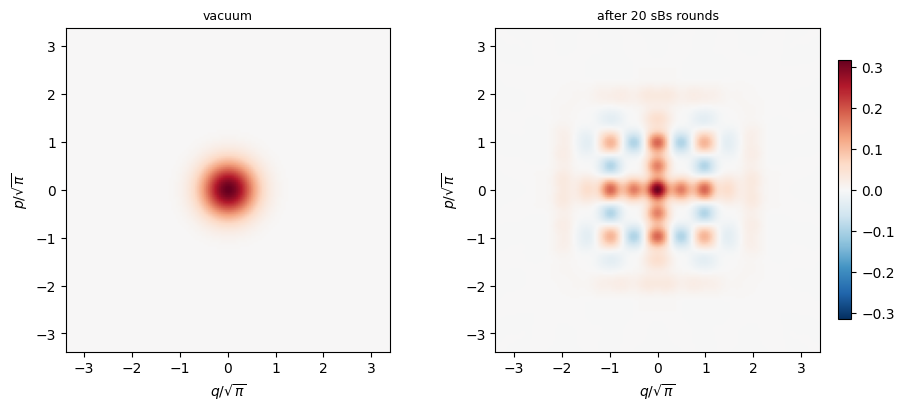

In [3]:
rho_vacuum = qt.fock_dm(N, 0)
rho_stabilized = sim.run_stabilization(rho_vacuum, n_rounds)

bloch, weight = sim.logical_bloch(rho_stabilized)
print("after", n_rounds, "sBs rounds: logical Bloch (X, Y, Z) =", np.round(bloch, 3), " weight in code space =", round(weight, 3))

fig, axs = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
im0 = sim.plot_wigner(axs[0], rho_vacuum, 'vacuum')
im1 = sim.plot_wigner(axs[1], rho_stabilized, f'after {n_rounds} sBs rounds')
fig.colorbar(im1, ax=axs[1], shrink=.8)
plt.show()

# Z herald (improved readout + D)

Herald g leaves |0_L>, herald e leaves |1_L>. From vacuum the two are not equally likely: the stabilized mixed state
keeps a logical Z bias (its Bloch Z above), which is the herald g/e asymmetry seen on the device.

In [4]:
for h in ['g', 'e']:
    p, rho_h = sim.herald_Z(rho_stabilized, h)
    bloch, weight = sim.logical_bloch(rho_h)
    print(f"herald {h}: probability {p:.3f}, logical Bloch (X, Y, Z) = {np.round(bloch, 3)}, code weight {weight:.3f}")

herald g: probability 0.790, logical Bloch (X, Y, Z) = [-0.02 -0.    1.  ], code weight 0.906
herald e: probability 0.210, logical Bloch (X, Y, Z) = [ 0.045  0.    -0.997], code weight 0.910


# All prepared states, as L4 acquires them

`prepare_states` runs the whole sequence for every branch. Herald e applies X_L, injection e applies Z_L, and each
later sBs round applies a known logical Pauli (an 'x' round Z_L, a 'z' round X_L); none are corrected, so every
branch is a definite state. The expected Bloch vector includes all of these.

In [5]:
states = sim.prepare_states()
print("frame of the later rounds (x_bit, z_bit):", sim.frame_after())
print(f"{'branch':7s} {'prob':>6s}   {'Bloch (X, Y, Z)':24s} {'expected':24s} {'fidelity in code':>16s} {'code weight':>11s}")
for name, (p, rho) in states.items():
    bloch, weight = sim.logical_bloch(rho)
    if name.endswith('all'):
        print(f"{name:7s} {p:6.3f}   {str(np.round(bloch, 3)):24s} {'(mixture)':24s} {'':>16s} {weight:11.3f}")
    else:
        expected = sim.expected_bloch(name)
        fidelity = (1 + bloch @ expected / np.linalg.norm(expected)) / 2
        print(f"{name:7s} {p:6.3f}   {str(np.round(bloch, 3)):24s} {str(np.round(expected, 3)):24s} {fidelity:16.3f} {weight:11.3f}")

frame of the later rounds (x_bit, z_bit): (1, 1)
branch    prob   Bloch (X, Y, Z)          expected                 fidelity in code code weight
Z_g      0.790   [ 0.027 -0.    -0.999]   [ 0.  0. -1.]                       0.999       0.967
H_gg     0.395   [-0.711 -0.026 -0.696]   [-0.707  0.    -0.707]              0.997       0.951
H_ge     0.395   [ 0.75   0.017 -0.654]   [ 0.707  0.    -0.707]              0.996       0.944
Z_e      0.210   [-0.036  0.     0.995]   [0. 0. 1.]                          0.998       0.958
H_eg     0.105   [-0.765  0.028  0.628]   [-0.707  0.     0.707]              0.992       0.938
H_ee     0.105   [ 0.72  -0.012  0.679]   [0.707 0.    0.707]                 0.995       0.931
Z_all    1.000   [ 0.014  0.    -0.583]   (mixture)                                       0.965
H_all    1.000   [ 0.008 -0.002 -0.399]   (mixture)                                       0.944


# Characteristic-function tomography (like L4)

L4 measures only the real part: the probe CD on qubit axis 0 moves the branches by +-xi/2, and the qubit readout
from g gives s_g = Re chi, from e s_e = -Re chi; the reported map is (s_g - s_e)/2. Square-code logical states are
parity-even, so Im chi is small and the real part carries the logical information: Re chi at xi_Z, xi_X and
xi_Y is <Z_L>, <X_L>, <Y_L> times the finite-energy envelope.

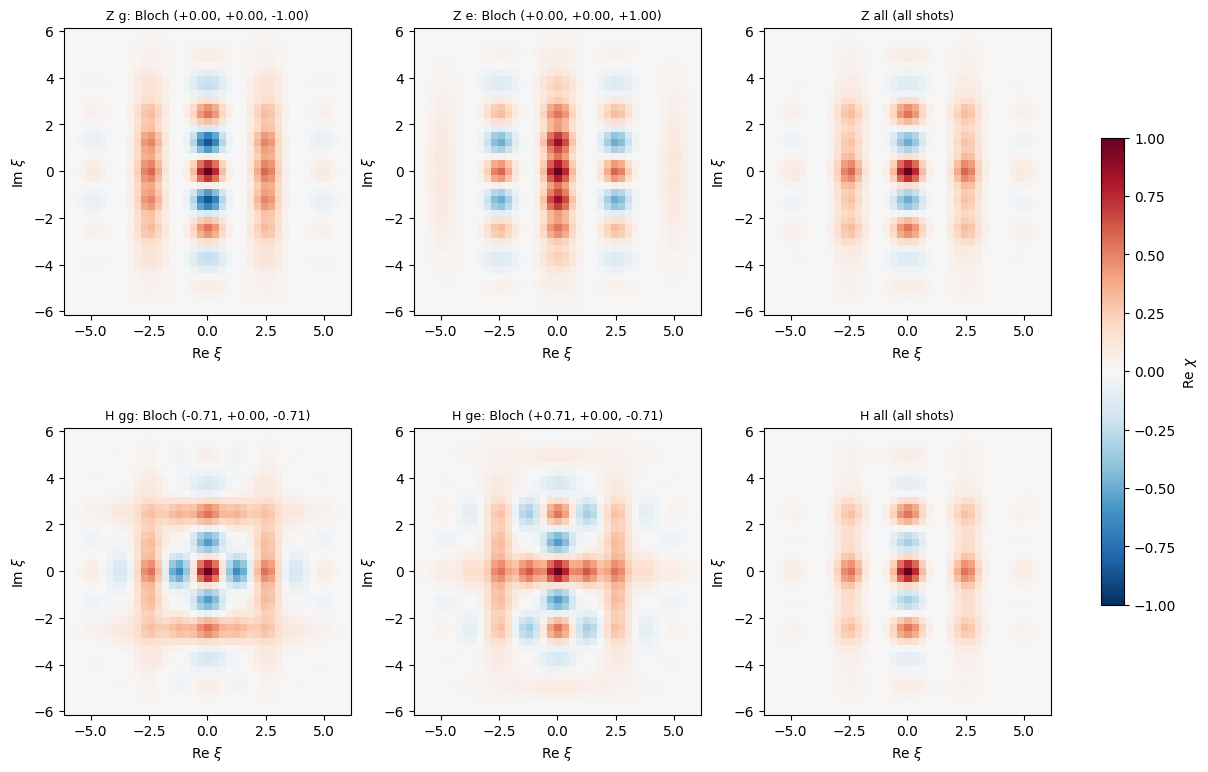

In [6]:
def title(name):
    if name.endswith('all'):
        return name.replace('_', ' ') + ' (all shots)'
    x, y, z = sim.expected_bloch(name)
    return f"{name.replace('_', ' ')}: Bloch ({x:+.2f}, {y:+.2f}, {z:+.2f})"

chi_maps = {}
for name in ['Z_g', 'Z_e', 'Z_all', 'H_gg', 'H_ge', 'H_all']:
    chi_maps[name] = sim.chi_map(states[name][1], re_values, im_values)

# GUI plot 1 of L4: row Z = herald g, herald e, all shots; row H = injection g and e after herald g, all shots
fig, axs = plt.subplots(2, 3, figsize=(12, 8), constrained_layout=True)
for ax, name in zip(axs.ravel(), ['Z_g', 'Z_e', 'Z_all', 'H_gg', 'H_ge', 'H_all']):
    image = sim.plot_chi(ax, chi_maps[name], re_values, im_values, title(name))
fig.colorbar(image, ax=axs, shrink=.6, label=r'Re $\chi$')
plt.show()

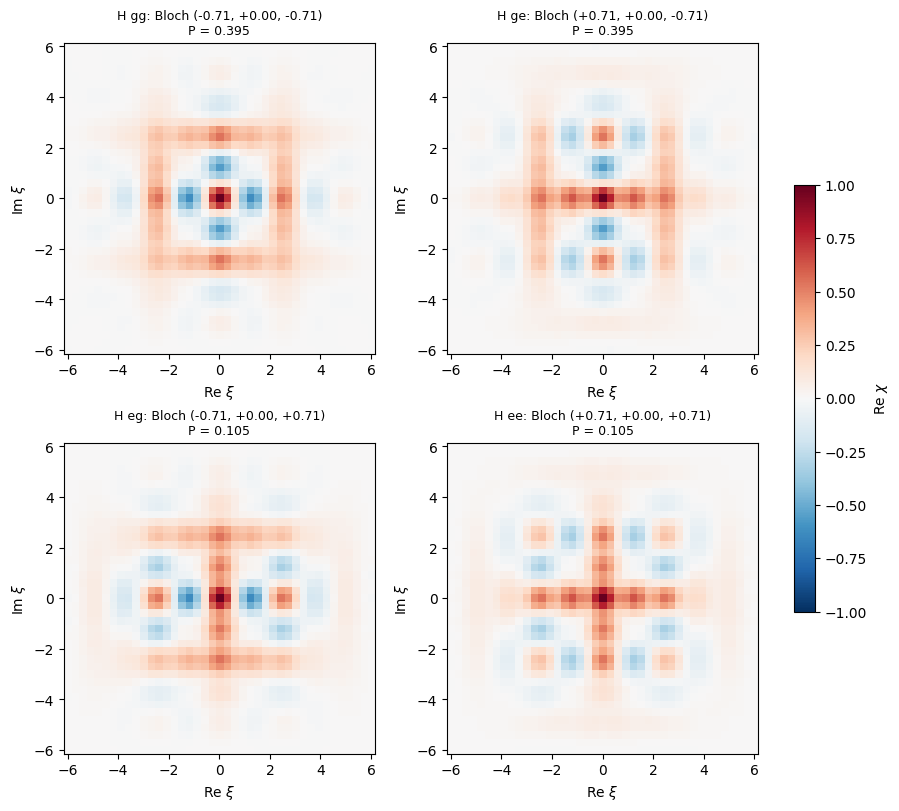

In [7]:
# GUI plot 2 of L4: the magic state in all four (herald, injection) branches
for name in ['H_eg', 'H_ee']:
    chi_maps[name] = sim.chi_map(states[name][1], re_values, im_values)

fig, axs = plt.subplots(2, 2, figsize=(9, 8), constrained_layout=True)
for ax, name in zip(axs.ravel(), ['H_gg', 'H_ge', 'H_eg', 'H_ee']):
    image = sim.plot_chi(ax, chi_maps[name], re_values, im_values, title(name) + f"\nP = {states[name][0]:.3f}")
fig.colorbar(image, ax=axs, shrink=.6, label=r'Re $\chi$')
plt.show()

In [8]:
# Re chi at the logical points (what the maps show at xi_Z, xi_X, xi_Y), and Im chi there
for name in ['Z_g', 'Z_e', 'H_gg', 'H_ge', 'H_eg', 'H_ee']:
    rho = states[name][1]
    values = [sim.chi(rho, sim.xi_logical[P]) for P in ['X', 'Y', 'Z']]
    print(f"{name:5s} chi at xi_X, xi_Y, xi_Z: " + ", ".join(f"{v.real:+.3f}{v.imag:+.3f}j" for v in values))

Z_g   chi at xi_X, xi_Y, xi_Z: -0.000+0.001j, +0.000-0.016j, -0.858+0.000j
Z_e   chi at xi_X, xi_Y, xi_Z: +0.000-0.001j, -0.000+0.017j, +0.853-0.000j
H_gg  chi at xi_X, xi_Y, xi_Z: -0.625-0.007j, -0.018-0.024j, -0.562+0.007j
H_ge  chi at xi_X, xi_Y, xi_Z: +0.626+0.010j, +0.010+0.004j, -0.563+0.006j
H_eg  chi at xi_X, xi_Y, xi_Z: -0.629-0.010j, +0.029+0.046j, +0.530-0.013j
H_ee  chi at xi_X, xi_Y, xi_Z: +0.629+0.007j, -0.016-0.024j, +0.530-0.012j


# Check: the simulated probe measurement equals Re chi

Same probe as the device (qubit g or e, CD on axis 0, Z readout); (s_g - s_e)/2 must equal Re Tr[rho D(xi)].

In [9]:
re_small = np.linspace(-4, 4, 9)
im_small = np.linspace(-4, 4, 9)
rho = states['H_gg'][1]
measured = sim.chi_map(rho, re_small, im_small, from_probe=True)
direct = sim.chi_map(rho, re_small, im_small, from_probe=False)
print("points compared:", measured.size, " max |(s_g - s_e)/2 - Re chi| =", np.max(np.abs(measured - direct)))

points compared: 81  max |(s_g - s_e)/2 - Re chi| = 1.0759236366425506e-07


# The input-phase calibration

`magic_input_phase` only turns the injected state about logical X: <X_L> stays near +0.7 while Y and Z change.
On the device the phase is scanned and the maximum of Re chi at xi_Z for herald g / injection g is kept.

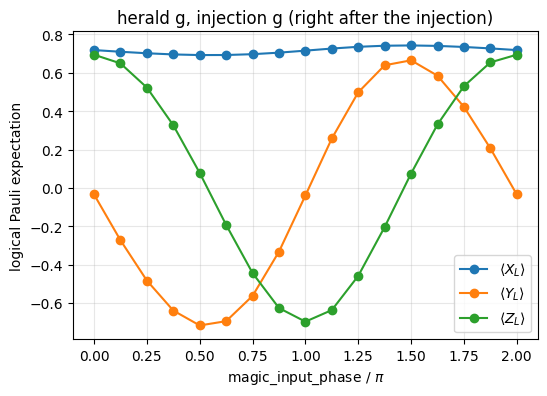

phase with max <Z_L>: 0.0 pi


In [10]:
p_g, rho_herald_g = sim.herald_Z(rho_stabilized, 'g')
phases = np.linspace(0, 2*np.pi, 17)
bloch_vs_phase = []
for phase in phases:
    sim.magic_input_phase = phase
    p, rho_gg = sim.inject_magic(rho_herald_g, 'g', 'g')
    bloch, weight = sim.logical_bloch(rho_gg)
    bloch_vs_phase.append(bloch)
sim.magic_input_phase = magic_input_phase     # restore
bloch_vs_phase = np.array(bloch_vs_phase)

plt.figure(figsize=(6, 4))
for k, label in enumerate(['X', 'Y', 'Z']):
    plt.plot(phases/np.pi, bloch_vs_phase[:, k], marker='o', label=rf'$\langle {label}_L\rangle$')
plt.xlabel(r'magic_input_phase / $\pi$')
plt.ylabel('logical Pauli expectation')
plt.title('herald g, injection g (right after the injection)')
plt.grid(True, alpha=.3)
plt.legend()
plt.show()
print("phase with max <Z_L>:", round(phases[np.argmax(bloch_vs_phase[:, 2])]/np.pi, 3), "pi")